In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from pathlib import Path

In [4]:
PROJECT_ROOT = Path.cwd().parents[0]

In [3]:
csv_path = Path(PROJECT_ROOT / "outputs" / "predictions_2021_2024_RF" / "RF_preds_standard_2021_2024.csv")   # change to your file
date_col = "Reference_date"              # change if needed
region_col = "Region"
horizon_col = "Horizon"
pred_col = "Pred_detrended"
obs_col = "Obs_detrended"
z_col = "Z_score"
season_col = "Season"

# Regions / seasons in desired plotting order
region_order = ["W", "SW", "MW", "SE", "NE"]
season_order = ["Winter", "Spring", "Summer", "Fall"]
horizon_order = [1, 2, 3, 4]

# Z-score bin centers and edges
z_centers = np.array([-1.5, -1.0, -0.5, 0.0, 0.5, 1.0, 1.5])
bin_width = 0.5
z_edges = np.arange(-1.75, 1.76, 0.5)  # gives bins centered on -1.5,...,1.5

# ----------------------------
# Load data
# ----------------------------
df = pd.read_csv(csv_path)


In [4]:
# ----------------------------
# Convert YYYYWW to season
# ----------------------------
df["Year"] = df[date_col] // 100
df["Week"] = df[date_col] % 100

def week_to_season(week):
    if week <= 8 or week >= 49:
        return "Winter"
    elif week <= 21:
        return "Spring"
    elif week <= 35:
        return "Summer"
    else:
        return "Fall"

df["Season"] = df["Week"].apply(week_to_season)

In [5]:
# Keep only needed columns and drop missing
df = df[[date_col, region_col, horizon_col, pred_col, obs_col, z_col, season_col]].dropna().copy()

# ----------------------------
# Bin z-scores
# ----------------------------
df["z_bin"] = pd.cut(
    df[z_col],
    bins=z_edges,
    labels=z_centers,
    include_lowest=True,
    right=False
)

# If you want to clip values outside [-1.75, 1.75), do that explicitly:
df = df[df["z_bin"].notna()].copy()
df["z_bin"] = df["z_bin"].astype(float)

# ----------------------------
# Compute squared error / RMSE
# ----------------------------
df["sq_err"] = (df[pred_col] - df[obs_col]) ** 2

In [6]:

rmse_df = (
    df.groupby(["Season", region_col, "z_bin", horizon_col], observed=False)["sq_err"]
      .mean()
      .reset_index()
)
rmse_df["RMSE"] = np.sqrt(rmse_df["sq_err"])

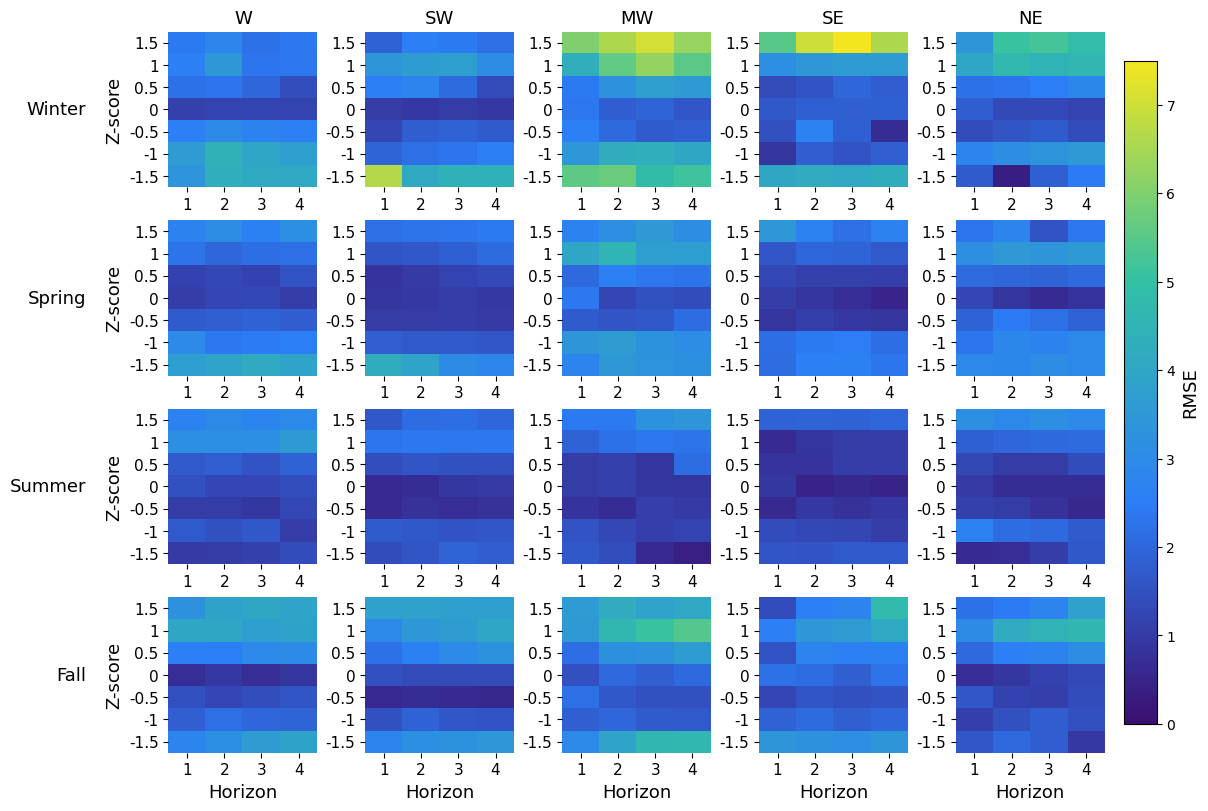

In [7]:
# Pivot into grids for plotting
# rows = z_bin, cols = horizon
grids = {}
for season in season_order:
    for region in region_order:
        sub = rmse_df[(rmse_df["Season"] == season) & (rmse_df[region_col] == region)]
        grid = (
            sub.pivot(index="z_bin", columns=horizon_col, values="RMSE")
               .reindex(index=z_centers, columns=horizon_order)
        )
        grids[(season, region)] = grid

# ----------------------------
# Color map similar to your figure
# blue -> cyan/green -> yellow
# ----------------------------
cmap = LinearSegmentedColormap.from_list(
    "paper_like",
    ["#3b0f70", "#2c7ef7", "#32c1a5", "#f4e61e"],
    N=200
)

# Common color scale across all panels
all_vals = pd.concat([g.stack() for g in grids.values() if g is not None])
vmin = np.floor(all_vals.min() * 2) / 2
vmax = np.ceil(all_vals.max() * 2) / 2
#vmin = 1
#vmax = 8.5
# ----------------------------
# Plot
# ----------------------------
fig, axes = plt.subplots(
    nrows=len(season_order),
    ncols=len(region_order),
    figsize=(12, 8),
    constrained_layout=True
)

for i, season in enumerate(season_order):
    for j, region in enumerate(region_order):
        ax = axes[i, j]
        grid = grids[(season, region)]

        im = ax.imshow(
            grid.values,
            origin="lower",
            aspect="auto",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )

        # Titles on top row
        if i == 0:
            ax.set_title(region, fontsize=13)

        # X ticks: horizon
        ax.set_xticks(range(len(horizon_order)))
        ax.set_xticklabels(horizon_order, fontsize=11)

        # Y ticks: z-score bins
        ax.set_yticks(range(len(z_centers)))
        ax.set_yticklabels([f"{z:g}" for z in z_centers], fontsize=11)

        # Row labels on leftmost column
        if j == 0:
            ax.set_ylabel("Z-score", fontsize=13)
            ax.text(
                -0.55, 0.5, season,
                transform=ax.transAxes,
                va="center", ha="right",
                fontsize=13
            )
        else:
            ax.set_ylabel("")

        # Bottom row x-labels
        if i == len(season_order) - 1:
            ax.set_xlabel("Horizon", fontsize=13)

        # Light panel border
        for spine in ax.spines.values():
            spine.set_visible(False)

# Single colorbar
cbar = fig.colorbar(im, ax=axes, shrink=0.92, pad=0.02)
cbar.set_label("RMSE", fontsize=13)
plt.savefig("Plots/ZbinPlotRF.png")
plt.show()




In [8]:
grid = grids[(season, region)]

In [7]:
import numpy as np
import matplotlib.pyplot as plt

In [5]:
import numpy as np
import matplotlib.pyplot as plt
csv_path = Path(PROJECT_ROOT / "outputs" / "predictions_2021_2024_RF" / "RF_preds_standard_2021_2024.csv")   # change to your fil

df = pd.read_csv(csv_path)

def qq_plot(ax, y_true, y_pred, title=""):
    # Sort values
    y_true_sorted = np.sort(y_true)
    y_pred_sorted = np.sort(y_pred)

    # Match lengths (in case of slight mismatch)
    n = min(len(y_true_sorted), len(y_pred_sorted))
    y_true_sorted = y_true_sorted[:n]
    y_pred_sorted = y_pred_sorted[:n]

    # Plot
    ax.scatter(y_true_sorted, y_pred_sorted, s=8, alpha=0.6)

    # 1:1 line
    min_val = min(y_true_sorted.min(), y_pred_sorted.min())
    max_val = max(y_true_sorted.max(), y_pred_sorted.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1)

    ax.set_title(title)
    ax.set_xlabel("Observed", fontsize=13)
    ax.set_ylabel("Predicted", fontsize=13)
    ax.grid(True, alpha=0.3)



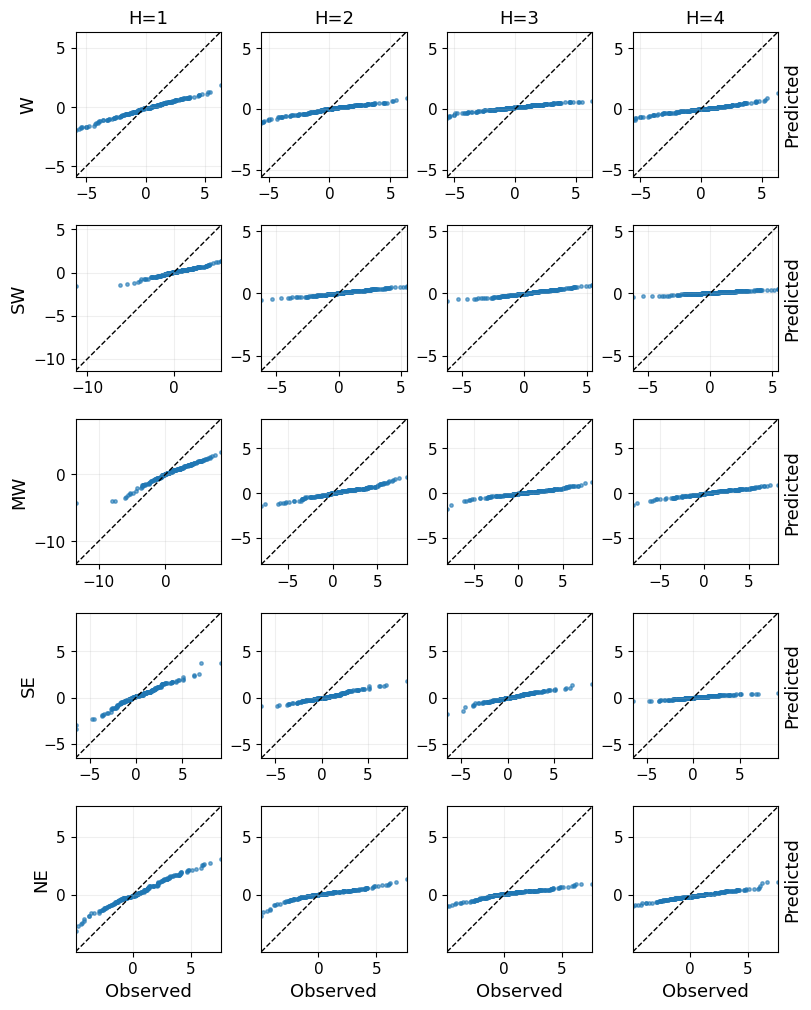

In [12]:
regions = ["W", "SW", "MW", "SE", "NE"]
horizons = [1, 2, 3, 4]

fig, axes = plt.subplots(
    nrows=len(regions),
    ncols=len(horizons),
    figsize=(8, 10),
    constrained_layout=True
)

for i, region in enumerate(regions):
    for j, horizon in enumerate(horizons):
        ax = axes[i, j]

        sub = df[(df["Region"] == region) & (df["Horizon"] == horizon)]

        y_true = sub["Obs_detrended"].values
        y_pred = sub["Pred_detrended"].values

        if len(y_true) == 0:
            continue

        # Sort
        y_true_sorted = np.sort(y_true)
        y_pred_sorted = np.sort(y_pred)

        n = min(len(y_true_sorted), len(y_pred_sorted))
        y_true_sorted = y_true_sorted[:n]
        y_pred_sorted = y_pred_sorted[:n]

        # Scatter
        ax.scatter(y_true_sorted, y_pred_sorted, s=6, alpha=0.6)

        # 1:1 line
        min_val = min(y_true_sorted.min(), y_pred_sorted.min())
        max_val = max(y_true_sorted.max(), y_pred_sorted.max())

        ax.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1)

        ax.set_xlim(min_val, max_val)
        ax.set_ylim(min_val, max_val)
        ax.set_aspect('equal', adjustable='box')

        # Titles and labels
        if i == 0:
            ax.set_title(f"H={horizon}", fontsize=13)

        if j == 0:
            ax.set_ylabel(region, fontsize=13)

        if i == len(regions) - 1:
            ax.set_xlabel("Observed", fontsize=13)

        if j == len(horizons) - 1:
            ax.yaxis.set_label_position("right")
            ax.set_ylabel("Predicted", fontsize=13)

        ax.tick_params(labelsize=11)
        ax.grid(alpha=0.2)
plt.savefig("Plots/QQPlots_RF.png")
plt.show()

#Shared axis
#z = sub["Z_score"].values
#colors = np.abs(z)

#ax.scatter(y_true_sorted, y_pred_sorted, c=colors[:n], cmap="viridis", s=6, alpha=0.7)

/tmp/ipykernel_314/1550536534.py:12: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df.groupby(["Region", "Horizon"], observed=False)


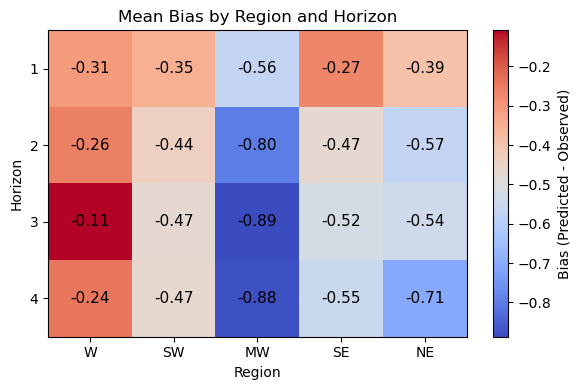

In [20]:
#bias

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import TwoSlopeNorm

# ----------------------------
# Compute bias
# ----------------------------
bias_df = (
    df.groupby(["Region", "Horizon"], observed=False)
      .apply(lambda g: np.mean(g["Pred_detrended"] - g["Obs_detrended"]))
      .reset_index(name="Bias")
)

# Pivot to matrix: rows = horizon, cols = region
region_order = ["W", "SW", "MW", "SE", "NE"]
horizon_order = [1, 2, 3, 4]

bias_matrix = (
    bias_df.pivot(index="Horizon", columns="Region", values="Bias")
            .reindex(index=horizon_order, columns=region_order)
)

# ----------------------------
# Plot heatmap
# ----------------------------
fig, ax = plt.subplots(figsize=(6, 4))

# Center colormap at zero
vmax = np.nanmax(np.abs(bias_matrix.values))
norm = TwoSlopeNorm(vmin=-0.9, vcenter=-0.5, vmax=0)

im = ax.imshow(
    bias_matrix.values,
    cmap="coolwarm",   # or "RdBu_r"
    #norm=norm,
    aspect="auto"
)

# Axis labels
ax.set_xticks(range(len(region_order)))
ax.set_xticklabels(region_order)

ax.set_yticks(range(len(horizon_order)))
ax.set_yticklabels(horizon_order)

ax.set_xlabel("Region", fontsize=13)
ax.set_ylabel("Horizon", fontsize=13)

# Optional: annotate values
for i in range(len(horizon_order)):
    for j in range(len(region_order)):
        val = bias_matrix.iloc[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=11)

# Colorbar
cbar = fig.colorbar(im, ax=ax)
cbar.set_label("Bias (Predicted - Observed)")

plt.title("Mean Bias by Region and Horizon")
plt.tight_layout()
plt.savefig("Plots/Bias_plot.png")
plt.show()

In [ ]:
# bias metrics
bias_df = (
    df.groupby(["Region", "Horizon"], observed=False)
      .apply(lambda g: pd.Series({
          "Bias": np.mean(g["Pred_detrended"] - g["Obs_detrended"]),
          "MAE": np.mean(np.abs(g["Pred_detrended"] - g["Obs_detrended"])),
          "RMSE": np.sqrt(np.mean((g["Pred_detrended"] - g["Obs_detrended"])**2)),
          "N": len(g)
      }))
      .reset_index()
)

,Reference_date,Observed,Predicted,Obs_detrended,Pred_detrended,Horizon,Region,Z_score
0,202106,268.648148,272.705561,-5.898702,-1.841288,1,W,-1.316462
1,202107,273.754786,274.447271,-1.278074,-0.585589,1,W,0.235794
2,202108,274.978508,275.498767,-0.613441,-0.093181,1,W,0.000021
3,202109,277.162459,275.431137,0.925956,-0.805366,1,W,1.345645
4,202110,276.235142,276.526807,-0.737544,-0.445880,1,W,-0.376554


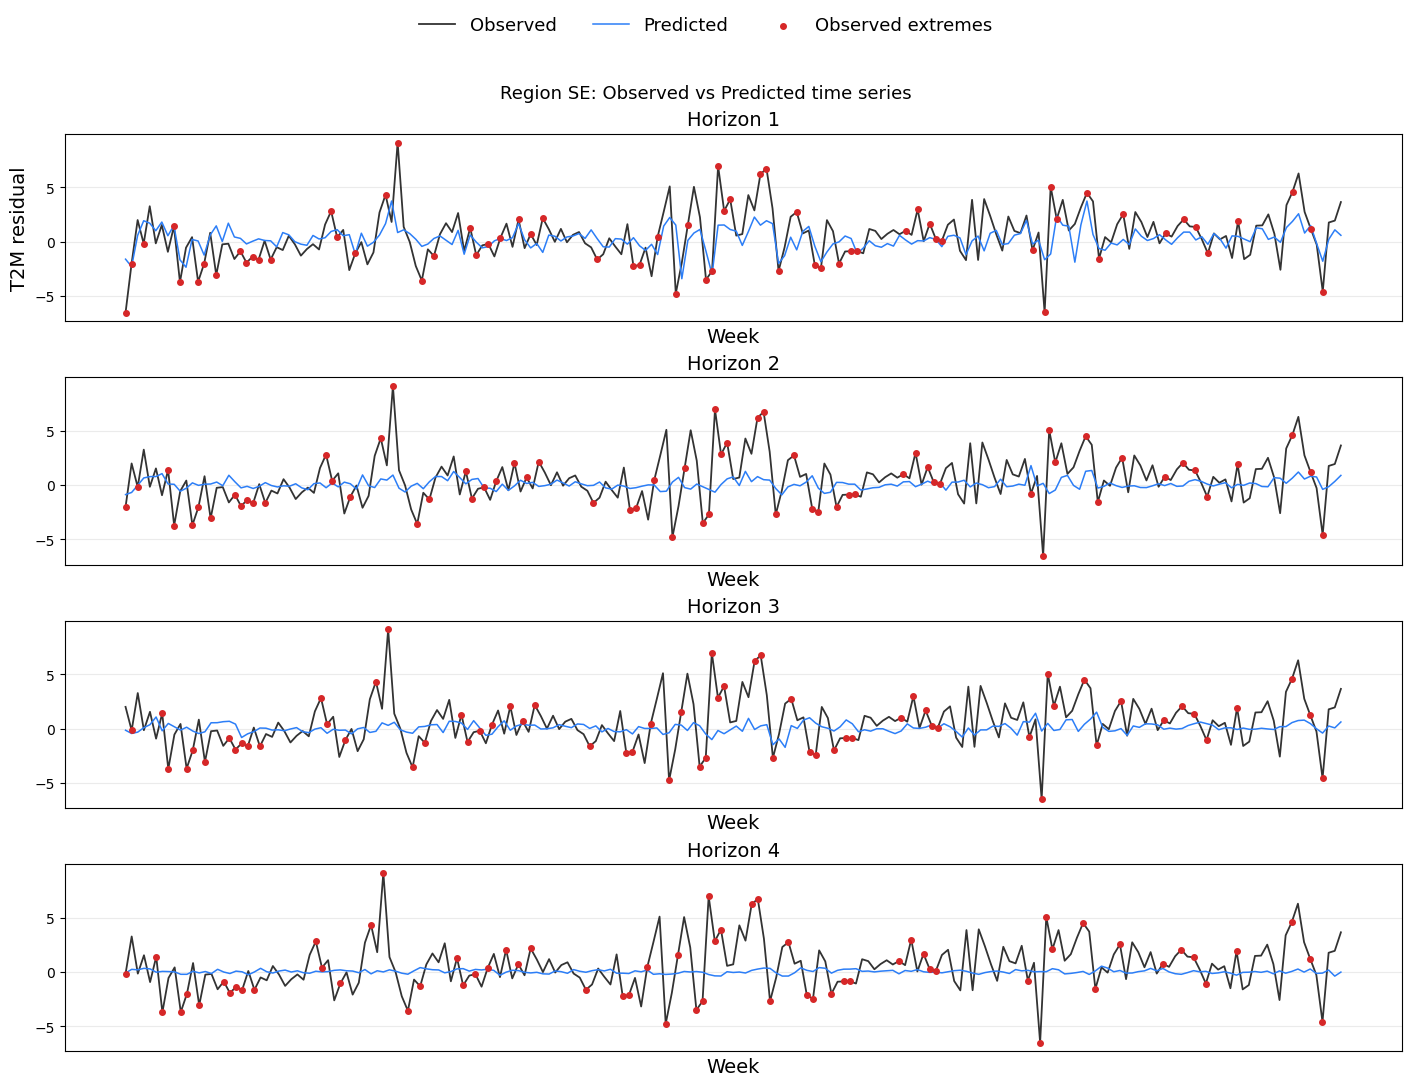

In [9]:
def format_yearweek(yw):
    yw = str(int(yw))
    return f"{yw[:4]}-{yw[4:]}"

def plot_obs_vs_pred_by_horizon(
    df,
    region="MW",
    ref_col="Reference_date",
    region_col="Region",
    horizon_col="Horizon",
    obs_col="Obs_detrended",
    pred_col="Pred_detrended",
    z_col="Z_score",
    extreme_thresh=1.0,
    figsize=(14, 10)
):
    sub = df[df[region_col] == region].copy()

    # Sort by reference date so lines are in time order
    sub = sub.sort_values([horizon_col, ref_col])

    horizons = [1, 2, 3, 4]

    # Common y-limits across panels
    ymin = min(sub[obs_col].min(), sub[pred_col].min())
    ymax = max(sub[obs_col].max(), sub[pred_col].max())
    pad = 0.05 * (ymax - ymin if ymax > ymin else 1.0)
    ymin -= pad
    ymax += pad

    fig, axes = plt.subplots(4,1, figsize=figsize, sharey=True, constrained_layout=True)

    for ax, h in zip(axes, horizons):
        hsub = sub[sub[horizon_col] == h].copy()
        hsub = hsub.sort_values(ref_col)

        x = np.arange(len(hsub))
        obs = hsub[obs_col].values
        pred = hsub[pred_col].values
        z = hsub[z_col].values

        extreme_mask = np.abs(z) > extreme_thresh

        # inside the loop, after x is defined:
        tick_idx = np.linspace(0, len(hsub)-1, 5, dtype=int)
        tick_labels = [format_yearweek(hsub.iloc[i][ref_col]) for i in tick_idx]
        
        # Observed and predicted lines
        ax.plot(x, obs, color="black", linewidth=1.3, alpha=.8, label="Observed")
        ax.plot(x, pred, color="#2c7ef7", linewidth=1.1,  label="Predicted")

        # Highlight observed extremes
        ax.scatter(
            x[extreme_mask],
            obs[extreme_mask],
            color="#d62728",
            s=16,
            zorder=3,
            label="Observed extremes" if h == 1 else None
        )
        ax.set_xticks(tick_idx)
        ax.set_xticklabels(tick_labels, rotation=45, fontsize=13)
        ax.set_title(f"Horizon {h}", fontsize=14)
        ax.set_ylim(ymin, ymax)
        ax.grid(alpha=0.25)

        # Make x-axis lighter / simpler
        ax.set_xticks([])

    axes[0].set_ylabel("T2M residual", fontsize=14)
    axes[0].set_xlabel("Week", fontsize=14)
    axes[1].set_xlabel("Week", fontsize=14)
    axes[2].set_xlabel("Week", fontsize=14)
    axes[3].set_xlabel("Week", fontsize=14)
    
    fig.suptitle(f"Region {region}: Observed vs Predicted time series", fontsize=13)

    # One shared legend
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.08), fontsize=13)
    plt.savefig(f"Plots/ObsVPred_TimeSeries_{region}.png", dpi=300, bbox_inches="tight")
    plt.show()
plot_obs_vs_pred_by_horizon(df, region="SE")

In [19]:
vmax

0.8874653916350206